# VLMs for a rover: the essentials

**Self-paced introduction · 2–3 hours · (Assuming Python and basic ML familiarity)**

You will follow one task—**“Approach the red chair”**—from camera input to wheel commands. Along the way, you will learn where language/vision models help, what supporting robotics code you need, and what changes when you run a model onboard.

Select a CPU runtime, and run cells in order. You do not need a robot, API key, GPU, ROS installation, or model download. The request/response examples are deliberately mocked; no neural model runs here.

| Part | Your focus | Time, including exercises |
|---|---|---:|
| 1 | LLMs, VLMs, and VLAs | 20 min |
| 2 | Camera, sensors, and rover state | 20 min |
| 3 | Prompts, API calls, and bounded outputs | 25 min |
| 4 | Differential drive and encoder feedback | 25 min |
| 5 | Edge inference and model adaptation | 30 min |
| 6 | Compare architectures | 15 min |
| Optional | ROS 2 and VLM integration | 25 min |

The main content will take about **135 minutes**; the ROS extension brings it to about **160 minutes**. Use the short reflection prompts to explain concepts in your own words. Four small exercises ask you to add or fix a few lines. Reference answers are at the end and aren't run automatically.

In [ ]:
import io, json, math
from PIL import Image, ImageDraw
from IPython.display import display, SVG

progress = {}
def check(number, test):
    try:
        test()
    except NotImplementedError:
        progress[number] = "TODO"
        print(f"Try it {number}: TODO — fill in the missing code, then rerun.")
    except Exception as error:
        progress[number] = "FIX NEEDED"
        print(f"Try it {number}: FIX NEEDED — {type(error).__name__}: {error}")
    else:
        progress[number] = "PASS"
        print(f"Try it {number}: PASS")

print("Ready.")

Ready.


## 1. LLM → VLM → VLA

An **LLM** learns patterns in language and generates text, usually one token at a time. A token is a piece of text, not necessarily a whole word. Tokens become numerical **embeddings**. Transformer **attention** lets representations combine information from other relevant positions. You do not need attention equations here.

The **context** is the information supplied for a prediction: instructions, conversation history, and other supported inputs. Context is limited and costs computation. A model does not automatically remember your rover's previous actions unless your application supplies history or maintains state.

A **VLM** adds visual input. Conceptually, an image encoder produces visual features/tokens, which a language model combines with your text to generate a response. Exact connectors and architectures vary. A model may resize or split images into patches, and more visual detail costs more memory and inference time.

Useful output is still fallible. A fluent description can be wrong. Also, a lower sampling temperature may reduce variation but does not establish correctness. An image is partial evidence--it might hide obstacles, distances, or what is outside the frame.

A **VLA** connects vision and language to robot actions through policy training, commonly using demonstrations. A **policy** maps observations and goals to actions. A VLA can output numeric actions, action tokens, or short action sequences; it need not produce explanatory text.

If you prompt a general VLM to emit `TURN_LEFT`, you have built a VLM-based action interface. You have not shown that it learned rover dynamics. Likewise, a VLA trained for an arm may output joint/end-effector actions that have no direct meaning for rover wheels.

| System | Input | Typical output |
|---|---|---|
| LLM | Text | Text |
| VLM | Image(s) + text | Description, answer, or structured text |
| VLM-based rover agent | Images + goal + selected state | Proposed decision, interpreted by your code |
| Robot-trained VLA | Visual observations + language, often robot state | Learned actions or action sequences |

**Check:** Explain why valid JSON, an accurate scene description, and successful navigation are three different achievements. Which one would a captioning benchmark (hint: evals how well a VLM describes images/videso) measure?

<details><summary>Reference answer</summary>
Valid JSON checks the interface. You can parse a response such as {"action":"FORWARD"} even when that action is wrong.
An accurate description checks perception. You might correctly describe “a red chair on the left” without knowing its distance, whether a route is clear, or how to steer toward it.
Successful navigation checks behavior over time. You need to choose useful actions, execute them, observe the result, and reach the intended target under your task's constraints.
A captioning benchmark primarily evaluates the description, often through comparison with reference captions. It does not establish correct wheel control or navigation. The point: test formatting, perception, and task completion separately.
</details>

### Two useful roles for a VLM

You can ask for **a bounded movement**, such as “turn left briefly,” or for **a semantic goal**, such as “navigate to the doorway on the left.” The second approach gives a navigation system more responsibility for geometry and execution.

Semantic recognition is not metric localization: seeing a chair does not automatically tell you its distance or its coordinates in a map. You still need a way to turn the recognized target into a reachable goal. A model's stated confidence is also not automatically a calibrated probability--you should not be relying on this.

## 2. The rover pipeline

The inputs we will use in our project serve different purposes:

- **Camera:** appearance, objects, and scene context.
- **Wheel encoders:** measured wheel rotation, useful for speed and odometry.
- **Optional other sensors:** IMU for motion/orientation; depth or ranging for additional geometric evidence.

For this introduction, you will use a camera and encoder readings. Encoders do not detect obstacles. Camera-only hazard detection can miss things, so you cannot assume that a language model or a few protective rules will prevent every crash.

Your application also maintains state: the current goal, timestamps, recent commands, estimated motion, and whether the rover is allowed to move. Give the VLM a small relevant summary; keep detailed wheel feedback in the local controller.

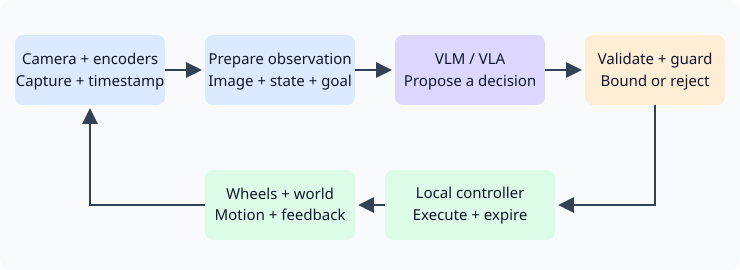

In [ ]:
# A diagram of responsibilities
display(SVG("""<svg xmlns="http://www.w3.org/2000/svg" width="740" height="270" viewBox="0 0 740 270">
<defs><marker id="arrow" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0,0 L8,4 L0,8" fill="#334155"/></marker></defs>
<rect width="740" height="270" rx="12" fill="#f8fafc"/>
<g font-family="sans-serif" font-size="15" text-anchor="middle" fill="#0f172a">
<rect x="15" y="35" width="150" height="70" rx="8" fill="#dbeafe"/><text x="90" y="64">Camera + encoders</text><text x="90" y="86">Capture + timestamp</text>
<rect x="205" y="35" width="150" height="70" rx="8" fill="#dbeafe"/><text x="280" y="64">Prepare observation</text><text x="280" y="86">Image + state + goal</text>
<rect x="395" y="35" width="150" height="70" rx="8" fill="#ddd6fe"/><text x="470" y="64">VLM / VLA</text><text x="470" y="86">Propose a decision</text>
<rect x="585" y="35" width="140" height="70" rx="8" fill="#ffedd5"/><text x="655" y="64">Validate + guard</text><text x="655" y="86">Bound or reject</text>
<rect x="385" y="170" width="170" height="70" rx="8" fill="#dcfce7"/><text x="470" y="198">Local controller</text><text x="470" y="220">Execute + expire</text>
<rect x="205" y="170" width="150" height="70" rx="8" fill="#dcfce7"/><text x="280" y="199">Wheels + world</text><text x="280" y="220">Motion + feedback</text>
</g>
<g fill="none" stroke="#334155" stroke-width="2" marker-end="url(#arrow)">
<path d="M165 70 H200"/><path d="M355 70 H390"/><path d="M545 70 H580"/>
<path d="M655 105 V205 H560"/><path d="M385 205 H360"/><path d="M205 205 H90 V110"/>
</g></svg>"""))

### Prepare inputs, without giving the model every raw signal

For an image request you may resize, JPEG-compress, and encode bytes in the provider's required format. Keep enough detail to recognize the target. “Video streaming” might initially mean selecting recent frames; a still-image API does not become motion-aware just because its images came from a video.

Timestamp capture and associate the eventual response with that observation. A latest-frame buffer helps avoid a growing queue of old images. Align sensor samples as well: combining a fresh image with an old speed reading can describe a state that never existed.

The synthetic image below only gives you something to package. The mocked API later will not inspect its pixels.

Compressed payload: 2747 bytes


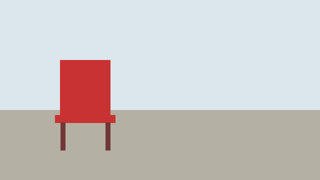

In [ ]:
frame = Image.new("RGB", (640, 360), "#dce6ed")
draw = ImageDraw.Draw(frame)
draw.rectangle((0, 220, 640, 360), fill="#b4b0a3")
draw.rectangle((120, 120, 220, 230), fill="#c83232")
draw.rectangle((110, 230, 230, 245), fill="#c83232")
draw.line((125, 245, 125, 300), fill="#713838", width=10)
draw.line((215, 245, 215, 300), fill="#713838", width=10)
display(frame.resize((320, 180)))

def encode_image(image):
    small = image.convert("RGB").copy()
    small.thumbnail((320, 240))
    buffer = io.BytesIO()
    small.save(buffer, format="JPEG", quality=75)
    return buffer.getvalue()

print("Compressed payload:", len(encode_image(frame)), "bytes")

### Try it 1: Assemble the observation

**Allow 5–8 minutes.** Implement `make_observation` using the provided encoder-to-speed function. `delta_left` and `delta_right` are wheel-shaft encoder tick changes over `dt_s`; the toy assumes 360 ticks per wheel revolution and no gearbox conversion.

Return exactly `image_jpeg`, `goal`, `speed_mps`, and `captured_at`. Use the mean of left/right wheel speeds as the rover's forward speed. `captured_at` is seconds on your rover's monotonic clock. Keep image bytes separate from the text summary; do not stringify them into the prompt.

Edit the TODO/bug below, rerun the cell, and read the check result. `TODO` or `FIX NEEDED` is expected on your first run. Add one case of your own after the checks pass.

<details><summary>Hint</summary>

Call the speed helper once per wheel. Get the average from the right and left values returned from the helper

Don't forget to encode the image (helper function in previous cell)

</details>

In [ ]:
def wheel_speed_from_ticks(delta_ticks, dt_s, radius_m=.05, ticks_per_rev=360):
    return (delta_ticks / ticks_per_rev) * 2 * math.pi * radius_m / dt_s

def make_observation(image, goal, delta_left, delta_right, dt_s, captured_at):
    # TODO: calculate two wheel speeds and return the four required fields (as json)
    # use the hint dropdown in the previous cell if needed
    raise NotImplementedError



def test_observation():
    obs = make_observation(frame, "Approach the red chair", 36, 36, .1, 12.0)
    assert set(obs) == {"image_jpeg", "goal", "speed_mps", "captured_at"}, "Return the four named fields"
    assert isinstance(obs["image_jpeg"], bytes), "Use encode_image(image)"
    assert math.isclose(obs["speed_mps"], math.pi*.1), "Check revolutions, circumference, and seconds"
    assert obs["captured_at"] == 12.0 and obs["goal"] == "Approach the red chair"
    turning = make_observation(frame, "Turn", -36, 36, .1, 12.0)
    assert math.isclose(turning["speed_mps"],0), "Opposite wheel speeds have zero mean forward speed"

check(1, test_observation)

Try it 1: TODO — fill in the missing code, then rerun.


## 3. Ask for a useful decision

Keep the model's job narrow. Specify the goal, allowed actions, and expected response shape. Ask for one short decision, then obtain new evidence; a long instruction to drive blindly is harder to correct.

For this toy, allow `FORWARD`, `TURN_LEFT`, `TURN_RIGHT`, or `STOP`. Your executor decides the bounded speed and duration for each. A production provider may support a JSON schema or enum constraint; request it where supported, then still validate locally.

An API call generally sends encoded input and instructions, waits for inference, and extracts the response. Authentication, image format, SDK, and structured-output syntax are provider-specific. Keep those details inside one replaceable adapter.

In [ ]:
ACTIONS = ("FORWARD", "TURN_LEFT", "TURN_RIGHT", "STOP")
SYSTEM_PROMPT = """You propose one short action for a differential-drive rover.
Use the supplied image, goal, and state. Allowed actions:
FORWARD, TURN_LEFT, TURN_RIGHT, STOP.
If the evidence is insufficient to propose motion, choose STOP.
Return only a JSON object with one field: action.
Your proposal will be checked by a local controller."""

def make_request(observation):
    return {
        "system": SYSTEM_PROMPT,
        "text": f"Goal: {observation['goal']}. Measured forward speed: {observation['speed_mps']:.2f} m/s.",
        "image_jpeg": observation["image_jpeg"],
    }

def mock_api(request, scripted_reply='{"action":"TURN_LEFT"}'):
    # Interface demo only: this ignores the image and goal.
    return scripted_reply

demo_observation = {"image_jpeg":encode_image(frame), "goal":"Approach the red chair",
                    "speed_mps":0.0, "captured_at":12.0}
request = make_request(demo_observation)
print(request["text"])
print("Mock response:", mock_api(request))

Goal: Approach the red chair. Measured forward speed: 0.00 m/s.
Mock response: {"action":"TURN_LEFT"}


### Your local code remains responsible

A prompt is a request, not an enforcement mechanism. Reject unsupported actions, malformed responses, and old observations. Use bounded transport timeouts--on failure, request STOP. In a real adapter, use secrets for credentials rather than embedding keys in a notebook (obviously).

**Observation age** runs from camera capture to execution, including preparation, queueing, network, inference, and dispatch. A response can be well formatted but too old to use. Measure elapsed time with a monotonic clock on the same device; clocks on different machines need to be treated carefully.

The “shadow code” is an explicit local guard/controller: motion limits, command expiry, and a stop path independent of model inference. Essentially, it is a protective layer running all the time regardless of what the agent is doing. Hazard checks need appropriate perception, as wheel encoders alone cannot tell whether the path is clear. A model-produced STOP also does not prove that the target was reached.

### Try it 2: Repair response handling

**Allow 8–10 minutes.** The function below currently trusts any action and ignores timing. Fix it so that it returns an allowed action only for a valid response and age.

- If `response` is `None`, return STOP (your mock transport timed out).
- If age is negative, nonfinite, or greater than 0.8 s, return STOP. Exactly 0.8 s is accepted.
- Parse a JSON object with exactly one key, `action`, whose value is in `ACTIONS`.
- On malformed JSON or invalid fields, return STOP.

You do not need to implement a network timeout here; this is the response boundary after a bounded request.

Edit the TODO/bug below, rerun the cell, and read the check result. `TODO` or `FIX NEEDED` is expected on your first run. Add one case of your own after the checks pass.

<details><summary>Hint</summary>

Check the age before parsing. Use `try/except` for malformed JSON; check the container before accessing fields.

</details>

In [ ]:
def safe_action(response, age_s):
    # BUG: no age check, no schema check, and no timeout handling.
    return json.loads(response)["action"]



def test_safe_action():
    assert safe_action('{"action":"TURN_LEFT"}',.1) == "TURN_LEFT", "Keep valid decisions"
    assert safe_action('{"action":"FORWARD"}',.8) == "FORWARD", "Accept the exact age boundary"
    for age in (.81,-.1,float("nan")):
        assert safe_action('{"action":"FORWARD"}',age) == "STOP", "Reject stale/invalid ages"
    for reply in (None, 'not JSON', '[]', '{"action":"FLY"}',
                  '{"action":"FORWARD","speed":99}', '{"action":["FORWARD"]}'):
        assert safe_action(reply,.1) == "STOP", f"Reject invalid response: {reply!r}"

check(2, test_safe_action)

Try it 2: FIX NEEDED — AssertionError: Reject stale/invalid ages


## 4. Convert decisions into differential-drive motion

Your rover can move and turn by changing the speeds of its left and right wheels. Use a consistent sign convention: positive forward speed moves forward; positive angular velocity turns left.

For wheel separation $L$, desired body speed $v$, and desired angular velocity $\omega$:

$$v_L=v-\frac{\omega L}{2},\qquad v_R=v+\frac{\omega L}{2}.$$

These are **wheel linear speeds in m/s**. For wheel radius $r$, divide by $r$ to obtain wheel angular speeds in rad/s. Neither value is directly a PWM duty cycle: your motor interface and feedback controller handle that conversion.

Equal speeds move straight, opposite speeds rotate in place, and fifferent forward speeds trace a curve.

### Try it 3: Fix the wheel-speed signs

**Allow 5–8 minutes.** The equations below have their signs reversed. Correct them to match the positive-left-turn convention above. Keep the return order `(left_mps, right_mps)`.

After the checks pass, predict the wheel speeds for a forward left curve with `v=.2`, `omega=.5`, and `separation=.3`, then run it. Explain why the right wheel must travel faster for this turn.

Edit the TODO/bug below, rerun the cell, and read the check result. `TODO` or `FIX NEEDED` is expected on your first run. Add one case of your own after the checks pass.

<details><summary>Hint</summary>

For a left turn in place, the left wheel goes backward and the right wheel goes forward.

</details>

In [ ]:
def wheel_speeds(v, omega, separation):
    # BUG: these signs cause positive omega to turn right.
    left = v + omega*separation/2
    right = v - omega*separation/2
    return left, right



def test_wheels():
    assert wheel_speeds(.2,0,.3) == (.2,.2), "Straight motion uses equal speeds"
    left,right = wheel_speeds(0,1,.3)
    assert math.isclose(left,-.15) and math.isclose(right,.15), "Positive omega must turn left"
    left,right = wheel_speeds(0,-1,.3)
    assert left > 0 and right < 0, "Negative omega must turn right"
    assert wheel_speeds(0,0,.3) == (0,0), "STOP means zero wheel speeds"

check(3,test_wheels)

Try it 3: FIX NEEDED — AssertionError: Positive omega must turn left


### Feedback: commanded motion is not measured motion

Encoders let your local controller estimate speed and adjust motor effort when actual speed differs from the target. This is **closed-loop control**. You can also integrate wheel travel to estimate movement (**odometry**):

$$\Delta s\approx(\Delta s_L+\Delta s_R)/2,\qquad
\Delta\theta\approx(\Delta s_R-\Delta s_L)/L.$$

Wheel radius, tick calibration, and slip affect these estimates. Spinning wheels can register travel while the rover barely moves. Odometry therefore drifts--this is why encoder feedback is not a complete navigation solution.

Keep two feedback loops in mind: your model sees fresh observations to revise decisions, while your motor controller reads encoders to track wheel speeds. The motor controller and watchdog continue locally even when model requests are slow.

**Check:** If an API stalls, which component must expire the current movement? If the wheels slip, why might both the model's old image and encoder-only odometry mislead you?

\Delta\theta\approx(\Delta s_R-\Delta s_L)/L.$$

Wheel radius, tick calibration, and slip affect these estimates. Spinning wheels can register travel while the rover barely moves. Odometry therefore drifts; encoder feedback is not a complete navigation solution.

Keep two feedback loops in mind: your model sees fresh observations to revise decisions, while your motor controller reads encoders to track wheel speeds. The motor controller and watchdog continue locally even when model requests are slow.

**Pause:** If an API stalls, which component must expire the current movement? If the wheels slip, why might both the model's old image and encoder-only odometry mislead you?

<details><summary>Reference answer</summary>

Your **rover-side executor/watchdog** must expire the command locally and request a stop when its deadline passes. It must not wait for another cloud response or depend on the blocked API-calling code to run the stop logic. The motor interface must actually enforce the expiry/stop behavior.

If the wheels slip, encoders can report wheel rotation without the corresponding movement across the floor, so integrated odometry becomes inaccurate. An old camera image describes an earlier scene and cannot confirm your current position or whether your last action worked.

**The point:** commanded motion, measured wheel rotation, and actual motion are different. Use fresh observations and appropriate feedback; stale images and encoders alone don't provide perfect state knowledge.

</details>

In [ ]:
# Provided example: measure motion over 0.1 seconds.
dt_s, radius_m, separation_m = .1, .05, .30
left_mps = wheel_speed_from_ticks(20,dt_s,radius_m)
right_mps = wheel_speed_from_ticks(30,dt_s,radius_m)
distance_m = (left_mps+right_mps)/2 * dt_s
heading_change_rad = (right_mps-left_mps)/separation_m * dt_s
print(f"Encoder estimate: travel {distance_m:.3f} m, heading change {heading_change_rad:.3f} rad")
print("This estimate assumes calibrated wheel-shaft ticks and no slip.")

Encoder estimate: travel 0.022 m, heading change 0.029 rad
This estimate assumes calibrated wheel-shaft ticks and no slip.


### Put the pieces together

The next cell uses your response validator and wheel conversion. Its observations and responses are scripted, so it demonstrates flow rather than autonomous navigation. Each command has a short lifetime; a real hardware executor must enforce that lifetime itself.

`hazard=True` represents a local perception check you would need to implement and validate separately. It is **not** inferred from the synthetic image or encoder readings. Observe how an apparently valid FORWARD decision gets vetoed, and how an old decision becomes STOP.

In [ ]:
# Simulation-only speeds. Do not treat these as calibrated hardware settings.
BODY_COMMANDS = {"FORWARD":(.15,0), "TURN_LEFT":(0,.5),
                 "TURN_RIGHT":(0,-.5), "STOP":(0,0)}
scripted_steps = [
    {"description":"Target left", "response":'{"action":"TURN_LEFT"}', "age_s":.2, "hazard":False},
    {"description":"Target centered", "response":'{"action":"FORWARD"}', "age_s":.2, "hazard":False},
    {"description":"Local hazard", "response":'{"action":"FORWARD"}', "age_s":.2, "hazard":True},
    {"description":"Old observation", "response":'{"action":"FORWARD"}', "age_s":1.2, "hazard":False},
]
if progress.get(2)=="PASS" and progress.get(3)=="PASS":
    for step in scripted_steps:
        action = safe_action(step["response"],step["age_s"])
        if step["hazard"]:
            action = "STOP"
        v,omega = BODY_COMMANDS[action]
        command = {"wheel_mps":wheel_speeds(v,omega,.3), "expires_in_s":.2}
        print(f"{step['description']:18} → {action:10} → {command}")
else:
    print("Complete Try it 2 and 3 and rerun their checks, then run this cell.")

Complete Try it 2 and 3 and rerun their checks, then run this cell.


## 5. Run a model onboard: what changes?

With **cloud inference**, you send observations to a remote model. You can experiment with capable models without carrying their compute, but network outages, delay, recurring fees, and camera-data transfer become part of your system.

With **edge inference**, a model runs on your rover's computer, such as a Jetson Orin Nano. You reduce network dependence and keep inference data local, but you take responsibility for memory, compute, power, cooling, and compatible software. Local does not automatically mean fast.

Consider a **Qwen vision-language variant** or **SmolVLM** as a model family to investigate, rather than a guarantee that any checkpoint will meet your needs. Qwen text-only models are not VLMs; SmolVLM and SmolVLA are different model families. Verify the exact checkpoint's input format, license, software requirements, and task behavior.

You should measure capture-to-decision latency, peak memory, and behavior on your own rover scenes. Measure sustained performance after warmup; a short benchmark may hide thermal limits. Text tokens/s alone omits image processing and does not tell you the rate of useful control decisions.

### A model can fit and still be too slow

Weight memory is roughly **parameter count × bytes per parameter**. FP16 uses about 2 bytes per parameter; INT8 about 1; packed INT4 about 0.5 before overhead. Runtime also needs activations, attention caches where applicable, temporary buffers, image processing, and the operating system. Jetson shares memory between CPU and GPU; its capacity is not all free model memory.

Latency also depends on image resolution, visual-token count, context length, generated output length, model architecture, and available kernels. You can often reduce work by selecting fewer frames, limiting history, or requesting a short action response—but you may lose information.

**Check:** Compare “the model uses 3 GB of weights” with “the system peaks at 7 GB.” Which number matters for fitting? What else matters for movement decisions arriving on time?

<details><summary>Reference answer</summary>

The total peak memory requirement matters for fitting. If the whole system peaks at 7 GB, budgeting only the 3 GB of weights misses another 4 GB of runtime/system use. Compare the total against usable device memory using consistent units, and leave headroom.
For timely movement decisions, also measure capture-to-execution delay, including image preparation, queues, inference, output decoding, and dispatch. Consider typical and slow-case delays, sustained performance under thermal/power limits, and your chosen rover speed. For cloud inference, include network variability.

Fitting is a memory question, while arriving soon enough to be useful is a latency and control question.
</details>

### Try it 4: Correct a memory estimate

**Allow 5–8 minutes.** The starter treats bits as bytes. Correct `weight_memory_gib`: multiply parameters by bits per parameter, convert bits to bytes, then convert bytes to binary GiB (`2**30`).

After it passes, compare the printed 0.5B and 3B examples. The hypothetical 8 GiB budget reserves 2 GiB for the rest of the system and 1.5 GiB for model working memory. Those reservations are placeholders; actual values require measurement. A passing estimate is not a deployment guarantee.

Edit the TODO/bug below, rerun the cell, and read the check result. `TODO` or `FIX NEEDED` is expected on your first run. Add one case of your own after the checks pass.

<details><summary>Hint</summary>

There are 8 bits in one byte. INT4 storage estimates ignore scale/metadata overhead.

</details>

In [ ]:
def weight_memory_gib(parameters,bits):
    # BUG: convert bits to bytes before converting to GiB.
    return parameters*bits / 2**30



def test_memory():
    assert math.isclose(weight_memory_gib(2**30,8),1), "8 bits per parameter equals 1 byte"
    assert math.isclose(weight_memory_gib(2**30,16),2), "16 bits equals 2 bytes"
    assert math.isclose(weight_memory_gib(2**30,4),.5), "Packed 4-bit weights use half a byte"
    for params in (.5e9,3e9):
        for bits in (16,4):
            weights = weight_memory_gib(params,bits)
            total = weights+2+1.5
            print(f"  {params/1e9:g}B / {bits}-bit: weights {weights:.2f} GiB, budget total {total:.2f} GiB, within 8 GiB? {total<=8}")

check(4,test_memory)

Try it 4: FIX NEEDED — AssertionError: 8 bits per parameter equals 1 byte


### Fine-tuning, distillation, and quantization solve different problems

| Method | What you change | What it helps with | What it does not guarantee |
|---|---|---|---|
| Fine-tuning | Train an existing model further on task data | Desired formats and task/domain behavior | Smaller size or correct unseen-scene behavior |
| Distillation | Train a smaller model using a larger teacher's outputs/behavior | Transfer useful behavior to a smaller model | Retaining all teacher capabilities or avoiding its errors |
| Quantization | Reduce numerical precision of weights and/or activations | Memory; sometimes latency and power | Speedup on every device or unchanged quality |

For fine-tuning, you need relevant examples and a held-out evaluation. LoRA can reduce the number of trainable parameters, but it does not inherently shrink the deployed backbone. For distillation, you still need data and training. For quantization, check whether the runtime supports efficient kernels for the chosen precision; lower precision can affect perception and action decisions.

You do not have to do all three. A sensible investigation is: evaluate a small pretrained VLM → benchmark it on your intended device → optimize precision/input workload if needed → adapt it only when you have evidence and data for a specific deficiency.

Loading a pretrained VLM gives you language/vision inference. Turning it into a robot-trained VLA would additionally require compatible action outputs and policy training; fine-tuning ordinary image captions alone does not accomplish that.

## 6. Compare ways to build the rover

**Cloud versus edge** is the problem of where inference runs. **ROS versus custom code** determine how we are organizing robotics components. You can use ROS with either cloud or local models.

| Approach | Main benefit | Main difficulty |
|---|---|---|
| Cloud VLM + local controller | Fast model experimentation; modest onboard inference needs | Network delay/outages, API costs, remote data transfer |
| Edge VLM + local controller | Local visual/language decisions | Compute limits, deployment work, capability tradeoffs |
| Edge VLA + local controller | Learned observation-to-action behavior | Compatible actions/embodiment, training data, evaluation |
| VLM + ROS navigation stack | Semantic goals plus established robotics components | Connect visual targets to geometry; integrate sensing/localization |
| Classical navigation using ROS, without a VLM | Explicit navigation logic for defined goals | Semantic/language goals require another component; still needs sensing |

ROS alone is not a navigation algorithm. The last row means you use appropriate perception, localization, planners, and controllers within ROS without a language/vision foundation model. Likewise, a VLM is not automatically a replacement for those components.

**Choose an architecture:** You have a camera, wheel encoders, intermittent Wi-Fi, and an onboard memory budget. Your goal is “approach the red chair.” Spend five minutes choosing a prototype and a later deployment approach. Give one advantage, one failure mode, and one measurement that would justify your choice. There is no single correct architecture for every task.

Then distinguish three evaluation questions: Did the response parse? Did the rover execute the intended movement? Did it reach the right target without unacceptable behavior? Good answers to the first two do not mean the same for the third.

### Finish the main path

You should now be able to explain:

1. Why a VLM-based agent differs from a robot-trained VLA.
2. What information comes from images versus encoder feedback.
3. Why local control continues independently of model requests.
4. How body velocity becomes differential-drive wheel speed.
5. Why a small model, a quantized model, and a task-adapted model are different choices.

Rerun the exercise cells after making changes; the checklist records your most recent check. You can stop here, or continue into the optional ROS section.

In [ ]:
for number in range(1,5):
    print(f"Try it {number}: {progress.get(number,'NOT RUN')}")
print("After changing an implementation, rerun its checks before trusting an old PASS.")

Try it 1: TODO
Try it 2: FIX NEEDED
Try it 3: FIX NEEDED
Try it 4: FIX NEEDED
After changing an implementation, rerun its checks before trusting an old PASS.


## Optional: ROS 2 and a VLM together

**Allow about 25 minutes.** You do not need to install ROS to follow this section.

ROS 2 provides middleware, message definitions, tools, and conventions for connecting robotics software. You split responsibilities into components that communicate rather than putting everything in one notebook loop.

| Concept | Plain meaning | Rover example |
|---|---|---|
| Node | A software component participating in ROS | Camera publisher, VLM adapter, controller |
| Topic | A named stream of messages | Camera frames, odometry, velocity commands |
| Service | A request followed by a response | Ask a component to reset an estimate |
| Action | A longer task with feedback and cancellation | Navigate to a pose |
| Coordinate frame | A reference for positions/orientations | Camera frame, robot body frame, odometry/map frame |

ROS actions are communication interfaces for long tasks; the word **action** in VLA refers to robot control outputs. They are not the same concept.

You can inspect messages, record/replay them for debugging, and visualize robot state. ROS distributes responsibilities; it does not make perception accurate or supply missing hardware feedback automatically.

### Two integration patterns

**Pattern A — bounded movement proposals.** A VLM node subscribes to camera/state data and produces a candidate movement. A guard validates and bounds it before a controller receives velocity commands. You must ensure that only the accepted command path controls the wheels, and keep command expiry local.

**Pattern B — semantic goals.** A VLM identifies what the user wants; perception/localization converts the target to a reachable pose; a navigation stack plans and follows a route. This can give you richer obstacle handling and recovery behavior, but it requires suitable geometric sensing and state estimation.

Nav2 is a navigation stack built on ROS 2; it is a separate layer with its own planners/controllers and supporting requirements. A camera and wheel encoders do not automatically supply everything needed for robust mapped navigation.

ROS's `diff_drive_controller` is another concrete component: it accepts body velocity commands, produces wheel commands, publishes odometry using feedback when configured, and supports command timeout. You still need a hardware interface, calibrated geometry, and appropriate configuration.

In [ ]:
# Conceptual message contents only; this does not import ROS or publish anything.
candidate_velocity = {"linear_x_mps": .15, "angular_z_radps": 0.0}
odometry_summary = {"x_m": 1.2, "y_m": .4, "heading_rad": .1, "speed_mps": .13}
navigation_goal = {"frame": "map", "x_m": 2.0, "y_m": 1.0, "heading_rad": 0.0}
print("Pattern A: accepted candidate → body velocity controller",candidate_velocity)
print("Pattern B: localized goal → navigation action",navigation_goal)
print("Encoder odometry gives an estimate, not a perfectly known map pose.")

Pattern A: accepted candidate → body velocity controller {'linear_x_mps': 0.15, 'angular_z_radps': 0.0}
Pattern B: localized goal → navigation action {'frame': 'map', 'x_m': 2.0, 'y_m': 1.0, 'heading_rad': 0.0}
Encoder odometry gives an estimate, not a perfectly known map pose.


### Frames and ownership are the important integration details

“The chair is left in the image” is a statement in camera coordinates. “Go to (2, 1)” needs a named frame and a way to estimate that position. Camera calibration, depth/geometry, localization, and frame transforms connect those statements. Avoid treating an image pixel coordinate as a map location.

Decide which component owns movement commands. If both a VLM and a navigation controller publish competing commands to the same actuator path, you can get contradictory behavior. A supervisor/arbiter should select the active source and allow cancellation or STOP.

**Optional reflection:** For “approach the red chair,” would you use Pattern A or B first? Which nodes would you need? Where would you reject an old model response? Which part would turn the chair's image location into a navigation goal?

<details>
<summary>Ref answer</summary>

For an initial camera-and-encoder prototype, you could start with Pattern A, using short bounded movement proposals. You would need camera/state publishers, a VLM adapter, a guard/supervisor, a differential-drive controller, and a hardware/encoder interface. The local guard should reject old model responses before execution; the executor should independently expire accepted commands.

For Pattern B, you would additionally need the components supporting localization, geometric target estimation, and navigation. A perception/localization component (not just the text response alone) would combine camera calibration, suitable depth or geometric evidence, and coordinate transforms to estimate the chair's target pose. You would usually choose an accessible approach pose near the chair, rather than navigating into it.
Essentially, ROS connects components, but it deosn't turn “left in the image” into a valid map goal automatically. You can choose Pattern B first if you already have a working navigation system and the necessary sensing.
</details>

### Continue learning

- [ROS 2 beginner tutorials](https://docs.ros.org/en/jazzy/Tutorials.html): begin with nodes, topics, and a Python publisher/subscriber. Then learn services and actions.
- [ROS 2 tf2 tutorials](https://docs.ros.org/en/jazzy/Tutorials/Intermediate/Tf2/Tf2-Main.html): understand coordinate frames and transformations.
- [Nav2 navigation concepts](https://docs.nav2.org/jazzy/getting_started/navigation_concepts/): identify the sensing/localization requirements before configuring navigation.
- [Differential-drive controller](https://control.ros.org/jazzy/doc/ros2_controllers/diff_drive_controller/doc/userdoc.html): connect velocity commands, wheel feedback, odometry, and timeouts.

These links use one ROS 2 distribution for consistency. Use documentation matching the distribution you eventually install.

## Model references and next steps

You can investigate [SmolVLM2's model card](https://huggingface.co/HuggingFaceTB/SmolVLM2-500M-Video-Instruct), [Qwen2.5-VL's architecture introduction](https://qwenlm.github.io/blog/qwen2.5-vl/), and [OpenVLA's repository](https://github.com/openvla/openvla) for contrasting VLM and robot-policy examples. These are examples, not claims of the latest or best checkpoint for your rover.

For hardware details, consult [NVIDIA's Jetson module lineup](https://developer.nvidia.com/embedded/jetson-modules). Before choosing a model/runtime, verify the exact device, usable memory, supported precision, and software compatibility.

Your next practical step can be replacing `mock_api` with one real provider adapter and evaluating a small set of recorded rover images. Keep motion disabled while testing perception/output behavior. After that, integrate a bounded rover-side executor and encoder feedback, then benchmark an edge alternative.

## Reference answers

Open these after trying each exercise. The examples below are text only; running the notebook does not fill your TODOs. Compare the behavior with your implementation, then rerun your checks.
<details><summary>Try it 1: one possible answer</summary>

```python
def make_observation(image, goal, delta_left, delta_right, dt_s, captured_at):
    left = wheel_speed_from_ticks(delta_left,dt_s)
    right = wheel_speed_from_ticks(delta_right,dt_s)
    return {"image_jpeg":encode_image(image), "goal":goal,
            "speed_mps":(left+right)/2, "captured_at":captured_at}
```

</details>

<details><summary>Try it 2: one possible answer</summary>

```python
def safe_action(response, age_s):
    if response is None or not math.isfinite(age_s) or not 0 <= age_s <= .8:
        return "STOP"
    try:
        payload = json.loads(response)
    except (ValueError,TypeError):
        return "STOP"
    if not isinstance(payload,dict) or set(payload) != {"action"}:
        return "STOP"
    action = payload["action"]
    return action if isinstance(action,str) and action in ACTIONS else "STOP"
```

</details>

<details><summary>Try it 3: one possible answer</summary>

```python
def wheel_speeds(v, omega, separation):
    return v-omega*separation/2, v+omega*separation/2
```

</details>

<details><summary>Try it 4: one possible answer</summary>

```python
def weight_memory_gib(parameters,bits):
    return parameters*bits/8/2**30
```

</details>